# OmniVision AI — Clasificación unificada con una sola CNN

**Objetivo.** Construir *un único* clasificador de imágenes con TensorFlow/Keras
(MobileNetV2 preentrenado) capaz de reconocer **67 categorías** provenientes de
**cuatro datasets** locales:

| Fuente | Categorías | Aporta |
|---|---|---|
| CIFAR-100 | 26 etiquetas finas seleccionadas | escenas, personas, dinosaurios, insectos, animales |
| Intel Image Classification | 6 clases | escenas urbanas/naturales |
| PlantVillage | 38 clases (especie + salud) | enfermedades de plantas |
| MosqVision-3K | 3 géneros | aedes, anopheles, culex |

Decisiones de diseño documentadas en `config/label_mapping.json` y `README.md`:

- Etiquetas equivalentes entre fuentes se **fusionan** (p. ej. *forest*,
  *mountain* y *sea* existen tanto en CIFAR-100 como en Intel; las tres
  variantes de personas de CIFAR se unifican en `person`).
- Se **respeta la partición oficial** de test de CIFAR-100 e Intel; el resto
  se divide 70/15/15 de forma estratificada (semilla 42).
- Se elimina **duplicados exactos (MD5)** con prioridad para el conjunto de
  prueba y se aplica un **tope de 600 imágenes por clase** en train+val.
- El **umbral de confianza** de la app no se inventa: se deriva del conjunto
  de validación.


In [1]:
# Setup
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.common import (IMG_SIZE, BATCH_SIZE, SEED, RESULTS_DIR, MODEL_PATH,
                        CATALOG_CSV, load_class_names, load_class_metadata)

np.random.seed(SEED)
pd.set_option("display.max_rows", 100)
print(f"Raíz: {ROOT}")
print(f"IMG_SIZE={IMG_SIZE}  BATCH_SIZE={BATCH_SIZE}  SEED={SEED}")


Raíz: C:\Users\nelso\Desktop\steven\proyectos\proyectoIdentificadorDeImagenes
IMG_SIZE=128  BATCH_SIZE=64  SEED=42


## 1. Preprocesamiento e integración de los cuatro datasets

`src/data_preprocessing.py` extrae CIFAR-100 (seleccionando 26 de sus 100
clases finas), recorre Intel/PlantVillage/MosqVision, valida cada imagen con
PIL, calcula MD5, elimina duplicados, construye los splits y el tope por
clase. Todo queda reproducible en `data/processed/catalog.csv`.

In [2]:
report = json.loads((RESULTS_DIR / "preprocessing_report.json").read_text(encoding="utf-8"))
print("Imagenes crudas por fuente:", report["raw_counts"])
print("Validas:", report["validas"], "| corruptas:", report["corruptas"],
      "| duplicados eliminados:", report["duplicados_eliminados"])
print("Registros finales:", report["final_counts"], "| clases:", report["num_clases"])

cat = pd.read_csv(CATALOG_CSV)
cat.groupby(["source", "split"]).size().unstack(fill_value=0)


Imagenes crudas por fuente: {'cifar100': 16200, 'intel': 17034, 'plantvillage': 48370, 'mosqvision': 3000}
Validas: 84604 | corruptas: 0 | duplicados eliminados: 1959
Registros finales: {'test': 13261, 'val': 5806, 'train': 28627} | clases: 67


split,test,train,val
source,,,
cifar100,2699,8852,1568
intel,3000,2793,487
mosqvision,308,547,226
plantvillage,7254,16435,3525


,clases
plant_disease,38
animal,12
scene,7
insect,5
mosquito,3
dinosaur,1
person,1


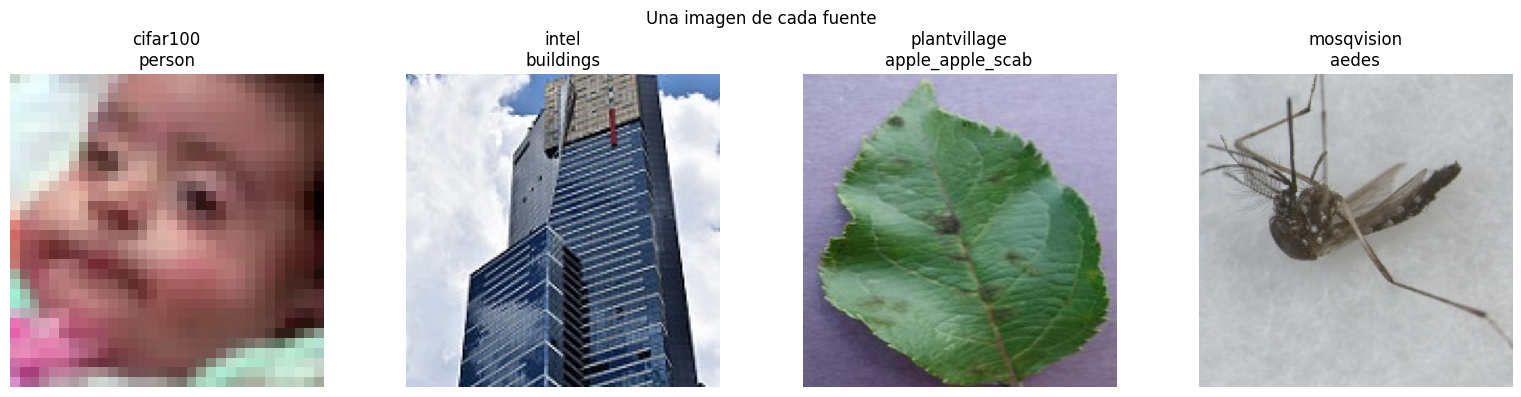

In [3]:
# Balance por grupo semántico y ejemplos por fuente
bal = json.loads((RESULTS_DIR / "balance_report.json").read_text(encoding="utf-8"))
meta = load_class_metadata()

por_grupo = pd.Series({l: meta["classes"][l]["group"] for l in meta["classes"]}).value_counts()
display(pd.DataFrame({"clases": por_grupo}))

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, source in zip(axes, ["cifar100", "intel", "plantvillage", "mosqvision"]):
    row = cat[cat.source == source].iloc[0]
    ax.imshow(plt.imread(ROOT / row.path))
    ax.set_title(f"{source}\n{row.unified_label}")
    ax.axis("off")
plt.suptitle("Una imagen de cada fuente")
plt.tight_layout()
plt.show()


## 2. Modelo único: MobileNetV2 + cabeza densa

Una sola red con 67 salidas softmax. La aumentación de datos y el
preprocesado propio de MobileNetV2 viven **dentro** del modelo
(`src/common.py::build_model`), de modo que inferencia y entrenamiento son
idénticos. La fase 1 entrena solo la cabeza; la fase 2 descongela las últimas
capas del backbone (fine-tuning).

In [4]:
import tensorflow as tf
from src.common import build_model

model, base = build_model(num_classes=67)
model.summary(line_length=90)
print("Capas entrenables al inicio:", sum(l.trainable for l in model.trainable_weights))


Model: "omnivision_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                          ┃ Output Shape                 ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)                   │ (None, 128, 128, 3)          │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ aug_flip (RandomFlip)                 │ (None, 128, 128, 3)          │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ aug_rotacion (RandomRotation)         │ (None, 128, 128, 3)          │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ aug_zoom (RandomZoom)                 │ (None, 128, 128, 3)          │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ aug_traslacion (RandomTranslation)    │ (None, 128, 128, 3)          │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ aug_contraste (RandomContrast)        │ (None, 128, 128, 3)          │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ aug_brillo (RandomBrightness)         │ (None, 128, 128, 3)          │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ preprocess_mobilenetv2 (Rescaling)    │ (None, 128, 128, 3)          │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_128 (Functional)     │ (None, 4, 4, 1280)           │       2,257,984 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ gap (GlobalAveragePooling2D)          │ (None, 1280)                 │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dropout (Dropout)                     │ (None, 1280)                 │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ salida (Dense)                        │ (None, 67)                   │          85,827 │
└───────────────────────────────────────┴──────────────────────────────┴─────────────────┘

 Total params: 2,343,811 (8.94 MB)

 Trainable params: 85,827 (335.26 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Capas entrenables al inicio: 2


## 3. Entrenamiento

Entrenado con `src/train.py --epochs1 15 --epochs2 8` (CPU, ~35 min).
Para reentrenar desde cero:

```powershell
.venv\Scripts\python -m src.train --epochs1 15 --epochs2 8
```

EarlyStopping con paciencia 3 sobre `val_accuracy`; se conserva la mejor fase.

Fase 1: {'best_val_accuracy': 0.8648, 'epochs_run': 15, 'seconds': 1272.7}
Fase 2: {'best_val_accuracy': 0.8839, 'epochs_run': 8, 'seconds': 821.6}
Mejor fase: {'val_accuracy': 0.8839, 'phase': 2}


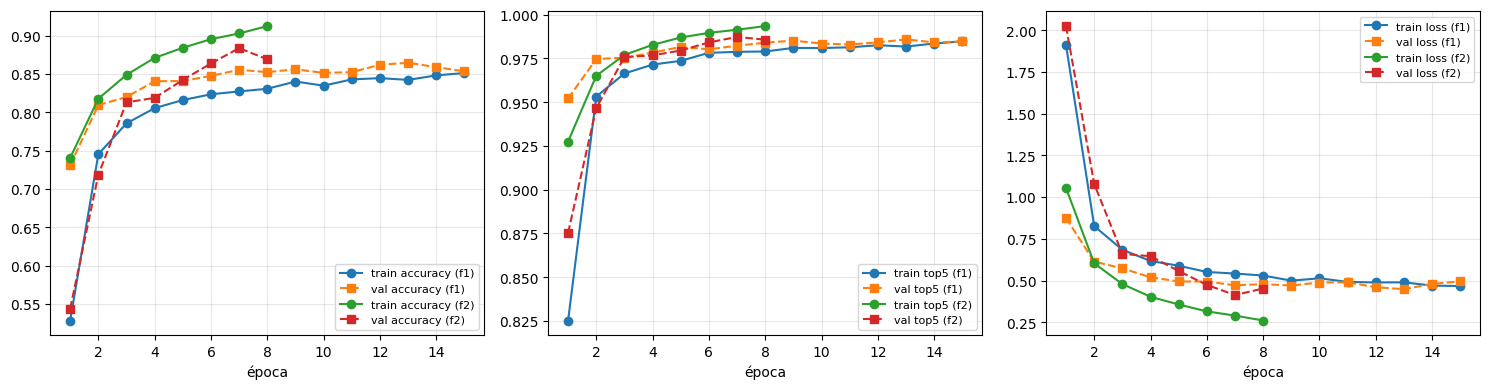

Duración total: fase1 21.2 min + fase2 13.7 min (CPU)


In [5]:
hist = pd.read_csv(RESULTS_DIR / "history.csv")
log = json.loads((RESULTS_DIR / "training_log.json").read_text(encoding="utf-8"))
print(f"Fase 1: {log['phase1']}")
print(f"Fase 2: {log['phase2']}")
print(f"Mejor fase: {log['best_phase']}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["accuracy", "top5", "loss"]):
    for phase, g in hist.groupby("phase"):
        ax.plot(g.epoch, g[col], marker="o", label=f"train {col} (f{phase})")
        vcol = f"val_{col}"
        if vcol in g:
            ax.plot(g.epoch, g[vcol], marker="s", ls="--", label=f"val {col} (f{phase})")
    ax.set_xlabel("época"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"Duración total: fase1 {log['phase1']['seconds']/60:.1f} min + "
      f"fase2 {log['phase2']['seconds']/60:.1f} min (CPU)")


## 4. Evaluación en el conjunto de prueba

`src.evaluate.py` mide accuracy, top-5, macro-F1, la matriz de confusión
completa, las métricas por clase y la exactitud por fuente. El umbral se
deriva del conjunto de **validación**.

In [6]:
test = json.loads((RESULTS_DIR / "test_report.json").read_text(encoding="utf-8"))
thr = json.loads((RESULTS_DIR / "threshold_analysis.json").read_text(encoding="utf-8"))

print(f"Accuracy test:        {test['accuracy']*100:.2f}%")
print(f"Top-5:                {test['top5_accuracy']*100:.2f}%")
print(f"Macro-F1:             {test['macro_f1']:.4f}")
print(f"Umbral (val):         {thr['selected']}")
print(f"En test con umbral:   cobertura {test['test_coverage_at_threshold']*100:.1f}% "
      f"-> precisión aceptada {test['test_precision_accepted']*100:.1f}%")
pd.Series(test["per_source_accuracy"], name="accuracy").to_frame()


Accuracy test:        87.96%
Top-5:                98.73%
Macro-F1:             0.8453
Umbral (val):         {'threshold': 0.47, 'coverage': 0.9719, 'precision': 0.9008}
En test con umbral:   cobertura 97.7% -> precisión aceptada 89.3%


,accuracy
cifar100,0.7647
intel,0.8700
mosqvision,0.8474
plantvillage,0.9276


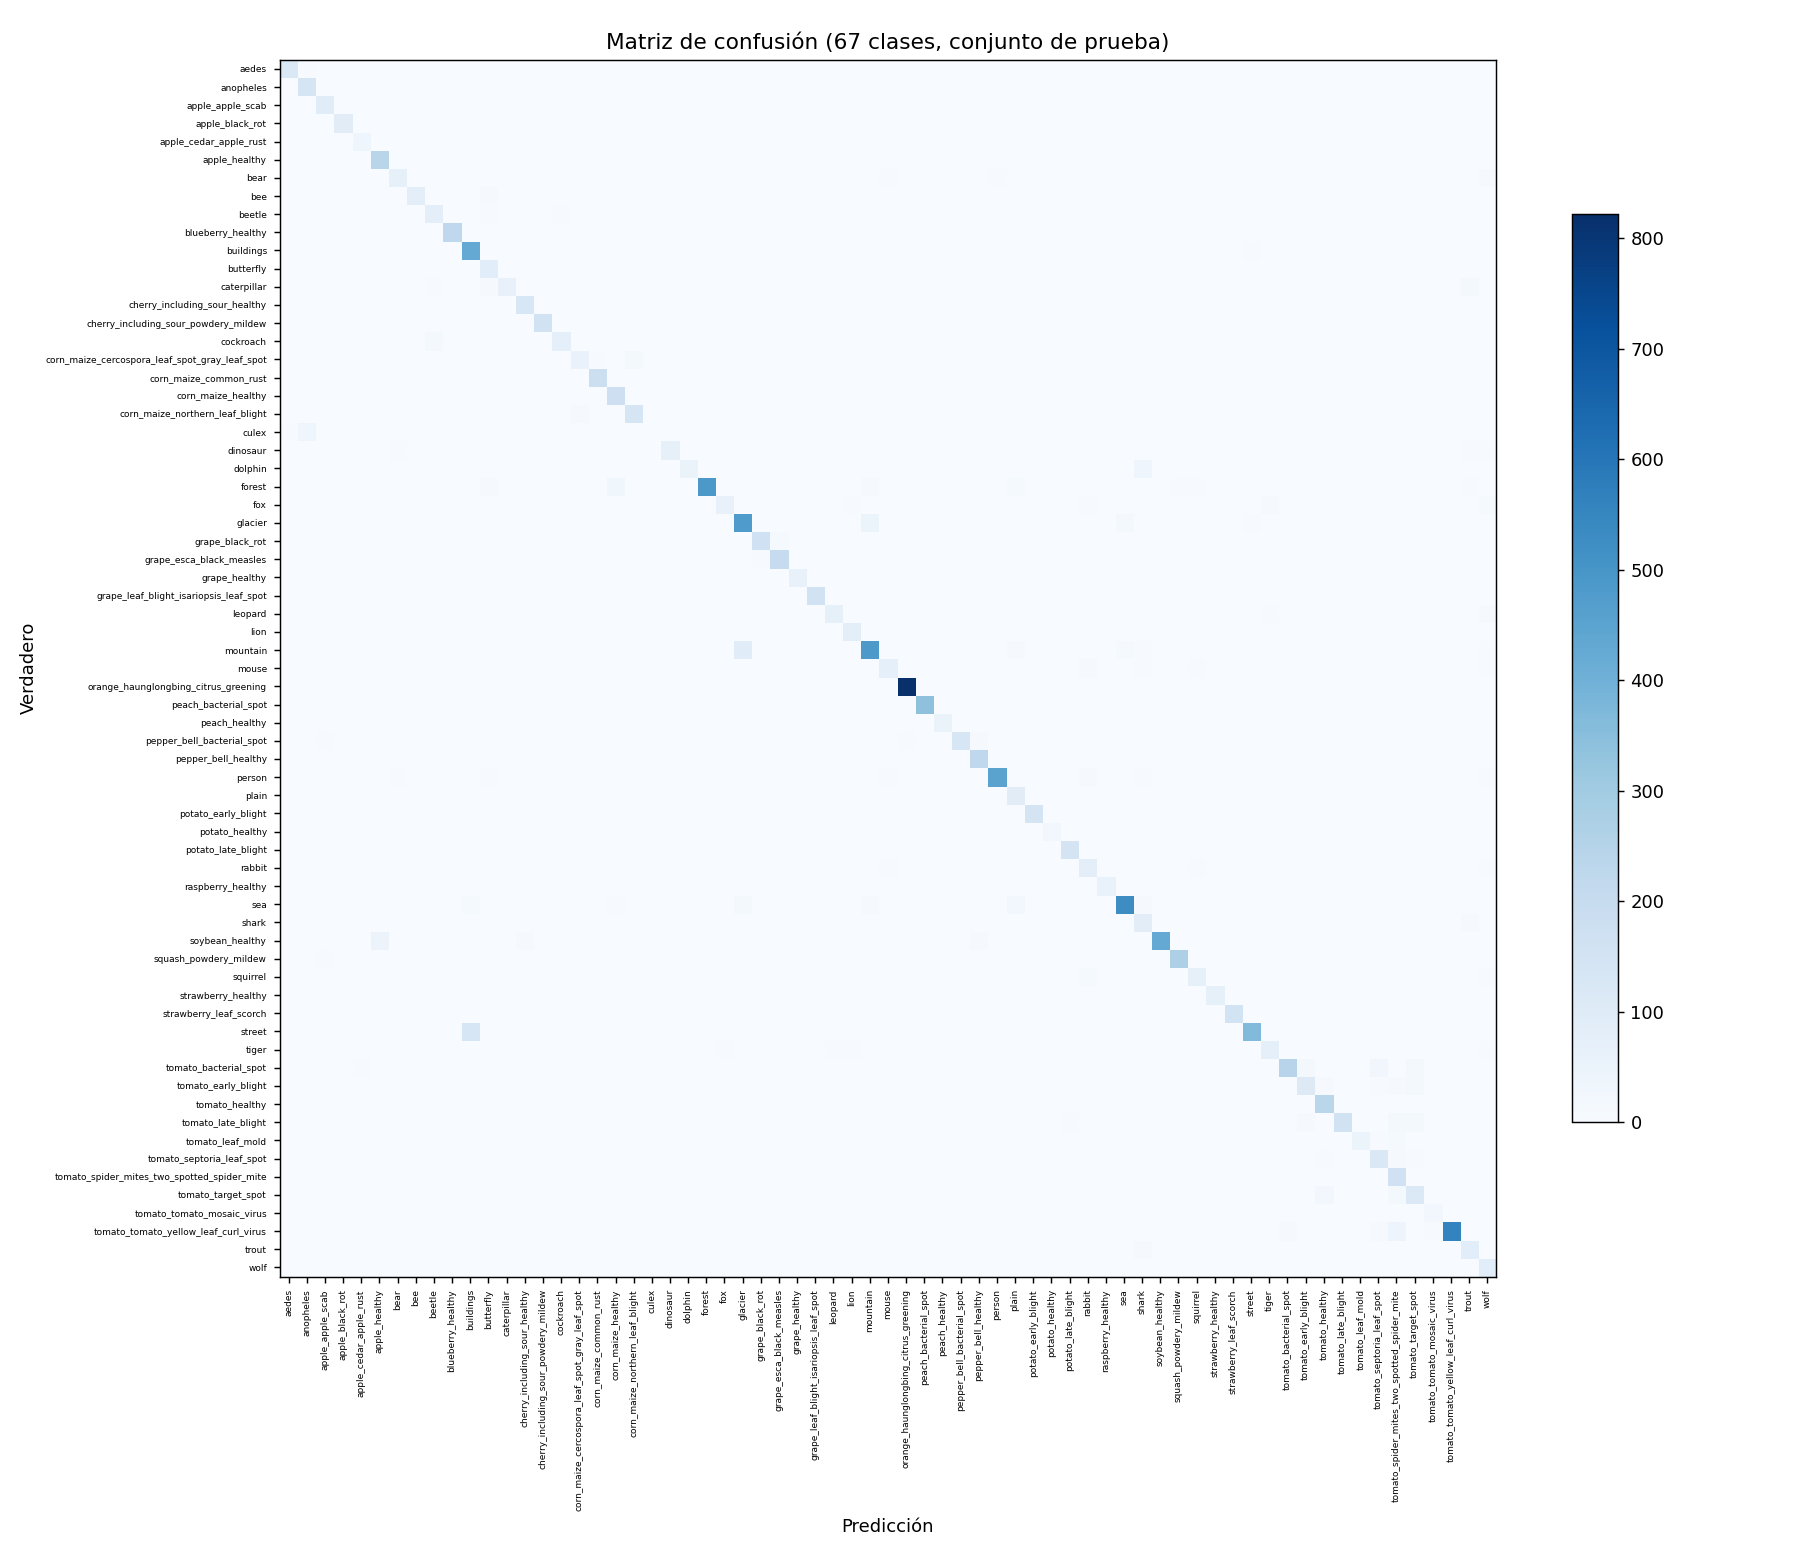

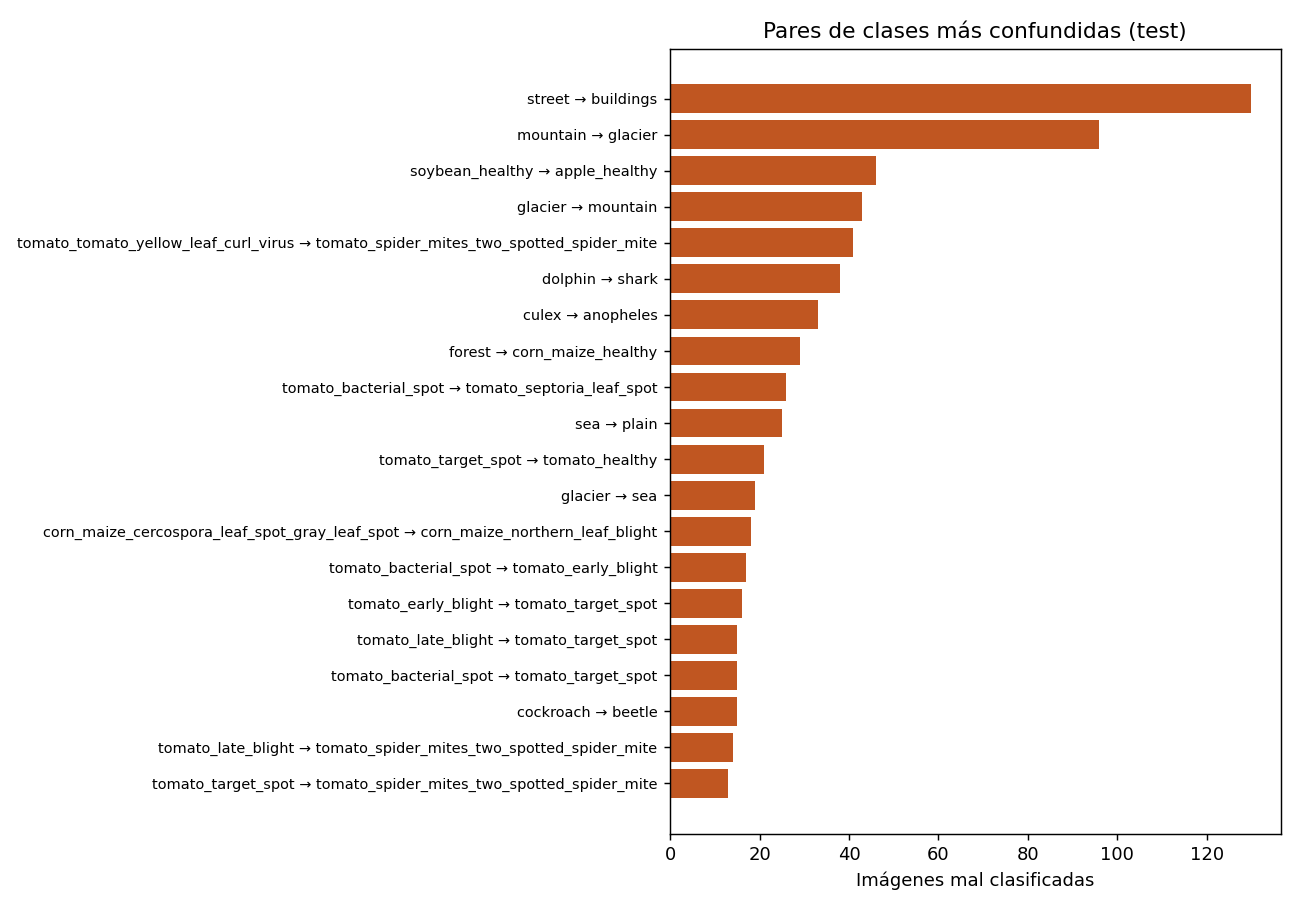

In [7]:
from IPython.display import Image, display
display(Image(filename=str(RESULTS_DIR / "confusion_matrix.png")))
display(Image(filename=str(RESULTS_DIR / "top_confusions.png")))


In [8]:
pc = pd.read_csv(RESULTS_DIR / "per_class_metrics.csv")
print("10 clases con menor F1:")
display(pc.nsmallest(10, "f1"))
print("10 clases con mayor F1:")
display(pc.nlargest(10, "f1"))


10 clases con menor F1:


,class,support,precision,recall,f1
20,culex,39,0.0000,0.0000,0.0000
47,shark,100,0.5217,0.8400,0.6437
22,dolphin,100,0.8689,0.5300,0.6584
66,wolf,100,0.5329,0.8900,0.6667
50,squirrel,100,0.6635,0.6900,0.6765
44,rabbit,100,0.5870,0.8100,0.6807
33,mouse,100,0.7030,0.7100,0.7065
6,bear,100,0.7473,0.6800,0.7120
24,fox,100,0.8101,0.6400,0.7151
62,tomato_target_spot,152,0.6845,0.7566,0.7188


10 clases con mayor F1:


,class,support,precision,recall,f1
45,raspberry_healthy,56,1.0000,1.0000,1.0000
51,strawberry_healthy,68,1.0000,1.0000,1.0000
3,apple_black_rot,93,1.0000,0.9892,0.9946
34,orange_haunglongbing_citrus_greening,826,0.9904,0.9952,0.9928
14,cherry_including_sour_powdery_mildew,158,0.9936,0.9810,0.9873
35,peach_bacterial_spot,345,0.9912,0.9826,0.9869
17,corn_maize_common_rust,179,0.9728,1.0000,0.9862
9,blueberry_healthy,225,0.9822,0.9822,0.9822
29,grape_leaf_blight_isariopsis_leaf_spot,161,0.9814,0.9814,0.9814
49,squash_powdery_mildew,275,0.9782,0.9782,0.9782


## 5. Inferencia con el modelo entrenado

`src/predict.py` expone la clase `Predictor`, la misma que usa la app
Streamlit (`app.py`). El resultado incluye nombre en español, grupo y
decisión de aceptación según el umbral.

In [9]:
from src.predict import Predictor

predictor = Predictor()
muestra = pd.read_csv(CATALOG_CSV).sample(3, random_state=SEED)
for _, row in muestra.iterrows():
    r = predictor.predict(str(ROOT / row.path), top_k=3)
    print(f"== {row.source} / real: {row.unified_label} ==")
    for t in r["top"]:
        print(f"   {t['name_es']:<40} {t['probability']*100:5.1f}%  ({t['group']})")
    print(f"   -> {'aceptada' if r['acepta'] else 'RECHAZADA'}\n")


== intel / real: forest ==
   Bosque                                   100.0%  (scene)
   Edificios                                  0.1%  (scene)
   Tigre                                      0.0%  (animal)
   -> aceptada

== plantvillage / real: potato_late_blight ==
   Patata — tizón tardío                    100.0%  (plant_disease)
   Manzano — sarna del manzano                0.0%  (plant_disease)
   Tomate — tizón tardío                      0.0%  (plant_disease)
   -> aceptada

== plantvillage / real: corn_maize_cercospora_leaf_spot_gray_leaf_spot ==
   Maíz — mancha por Cercospora (mancha gris)  70.5%  (plant_disease)
   Maíz — tizón foliar del norte             29.4%  (plant_disease)
   Edificios                                  0.0%  (scene)
   -> aceptada



## 6. Conclusiones

- **Una sola CNN** con 67 salidas alcanza **87,96 % de accuracy** y
  **98,73 % de top-5** en un conjunto de prueba de 13.261 imágenes
  heterogéneas (macro-F1 0,845).
- La fusión de etiquetas equivalentes entre fuentes (forest/mountain/sea,
  personas unificadas) evita clases redundantes sin degradar el rendimiento.
- El **umbral 0,47** derivado en validación ofrece ~90 % de precisión entre
  las predicciones aceptadas con ~97 % de cobertura: la app puede mostrar
  «sin confianza» de forma honesta.
- Las clases de menor rendimiento (culex, tiburón, delfín, lobo) concentran
  la confusión con especies visualmente parecidas: un límite documentado del
  dataset, no del pipeline.

### Cómo reproducir todo (PowerShell)

```powershell
.venv\Scripts\python -m src.data_preprocessing --force
.venv\Scripts\python -m src.train --epochs1 15 --epochs2 8
.venv\Scripts\python -m src.evaluate
.venv\Scripts\python -m src.predict ruta\a\imagen.jpg
.venv\Scripts\streamlit run app.py
```
